# Estadística Descriptiva: Función de Distribución Acumulada empírica y Gráficos Q-Q Plots

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.distributions.empirical_distribution import ECDF
import statsmodels.api as sm
import scipy.stats as stats

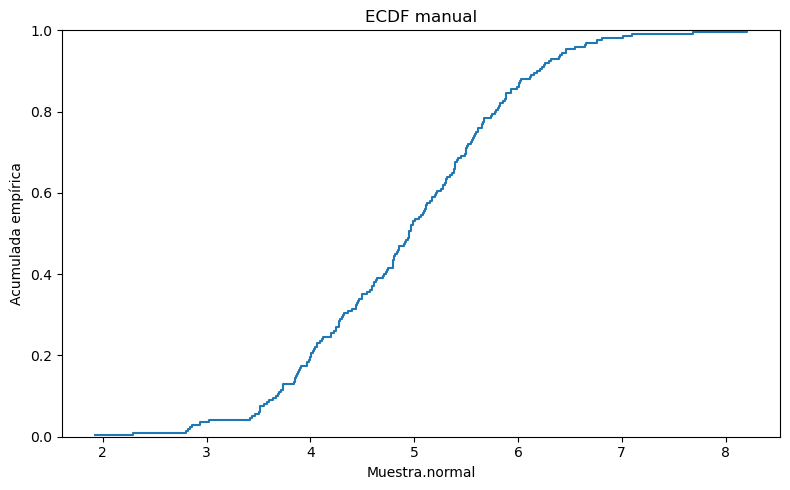

In [2]:
# A mano: función de distribución acumulada empírica (ECDF) construida manualmente
np.random.seed(641)
n = 200
m_normal = np.random.normal(loc=5, scale=1, size=n)
x_sorted = np.sort(m_normal)
y_ecdf = np.arange(1, n + 1) / n

plt.figure(figsize=(8, 5))
plt.step(x_sorted, y_ecdf, where='post')
plt.ylim(0, 1)
plt.xlabel('Muestra.normal')
plt.ylabel('Acumulada empírica')
plt.title('ECDF manual')
plt.tight_layout()
plt.show()

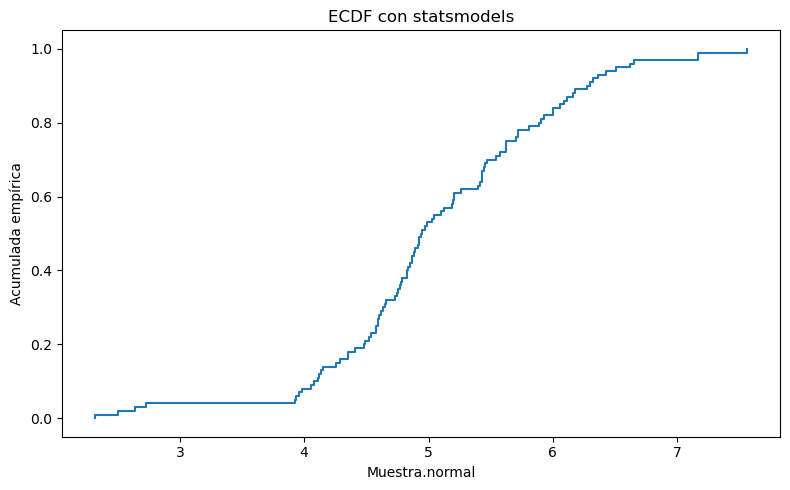

In [3]:
# Con la función ECDF
n = 100
m_normal = np.random.normal(loc=5, scale=1, size=n)
Fn = ECDF(m_normal)

plt.figure(figsize=(8, 5))
plt.step(Fn.x, Fn.y, where='post')
plt.xlabel('Muestra.normal')
plt.ylabel('Acumulada empírica')
plt.title('ECDF con statsmodels')
plt.tight_layout()
plt.show()

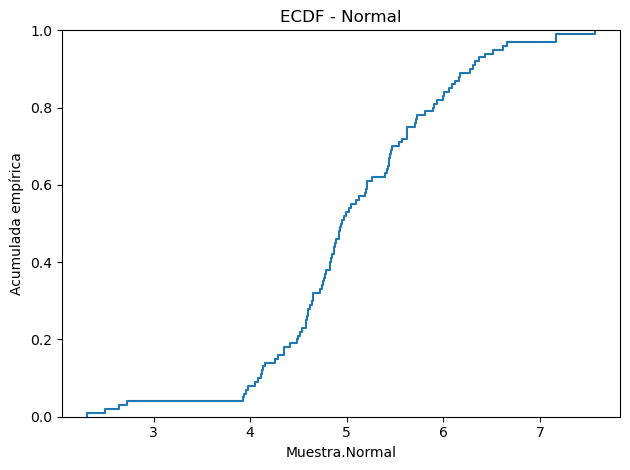

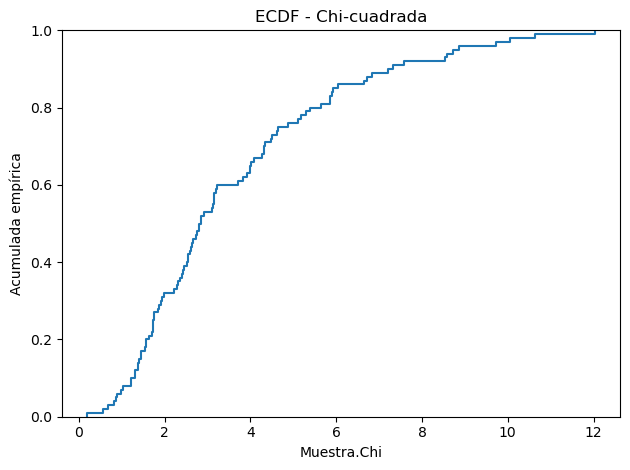

In [4]:
# ECDF con seaborn
m_chi = np.random.chisquare(df=4, size=n)
datosmios = pd.DataFrame({
    'm.normal': m_normal,
    'm.chi': m_chi
})

sns.ecdfplot(data=datosmios, x='m.normal')
plt.xlabel('Muestra.Normal')
plt.ylabel('Acumulada empírica')
plt.title('ECDF - Normal')
plt.tight_layout()
plt.show()

sns.ecdfplot(data=datosmios, x='m.chi')
plt.xlabel('Muestra.Chi')
plt.ylabel('Acumulada empírica')
plt.title('ECDF - Chi-cuadrada')
plt.tight_layout()
plt.show()

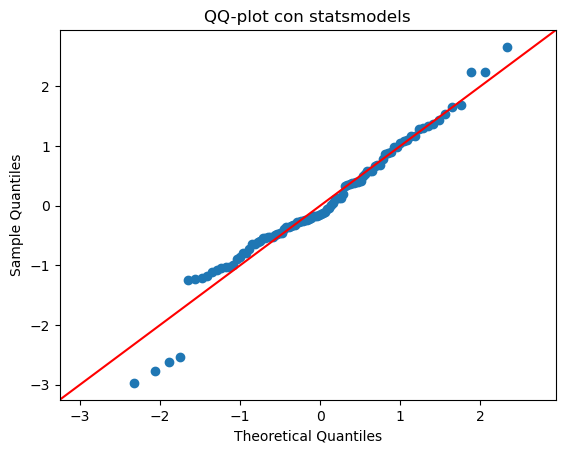

In [5]:
# Construimos los QQplots en Python con la función qqplot de la librería statsmodels
# QQ-plot
sm.qqplot(m_normal, fit = True, line='45')
plt.title('QQ-plot con statsmodels')
plt.show()

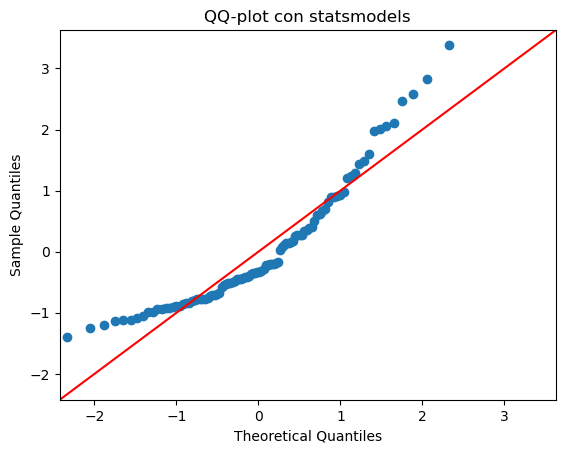

In [6]:
# QQ-plot
sm.qqplot(m_chi, fit = True, line='45')
plt.title('QQ-plot con statsmodels')
plt.show()

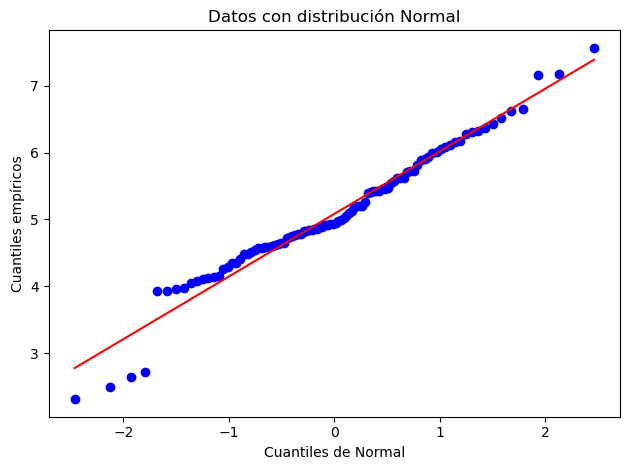

In [8]:
# Construimos los QQplots en Python con la función probplot del paquete stats de la librería scipy
# Gráfico QQ para m.normal
stats.probplot(m_normal, dist='norm', plot=plt)
plt.xlabel('Cuantiles de Normal')
plt.ylabel('Cuantiles empíricos')
plt.title('Datos con distribución Normal')
plt.tight_layout()
plt.show()

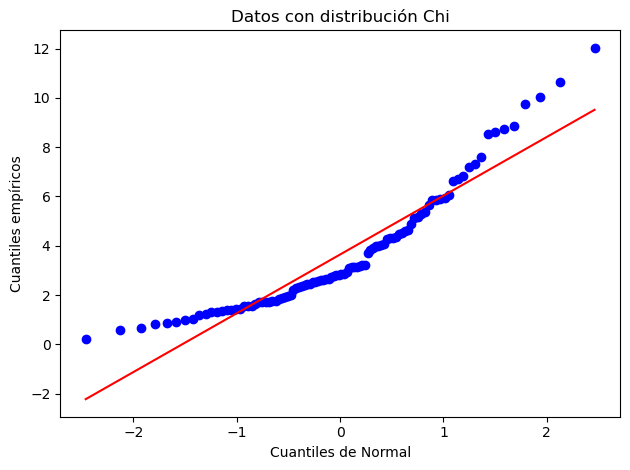

In [9]:
# Gráfico QQ para m.chi
stats.probplot(m_chi, dist='norm', plot=plt)
plt.xlabel('Cuantiles de Normal')
plt.ylabel('Cuantiles empíricos')
plt.title('Datos con distribución Chi')
plt.tight_layout()
plt.show()

In [12]:
# Dataset mtcars
mtcars = sm.datasets.get_rdataset('mtcars', 'datasets').data
mtcars.describe()

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
count,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.0000
mean,20.090625,6.187500,230.721875,146.687500,3.596563,3.217250,17.848750,0.437500,0.406250,3.687500,2.8125
std,6.026948,1.785922,123.938694,68.562868,0.534679,0.978457,1.786943,0.504016,0.498991,0.737804,1.6152
min,10.400000,4.000000,71.100000,52.000000,2.760000,1.513000,14.500000,0.000000,0.000000,3.000000,1.0000
25%,15.425000,4.000000,120.825000,96.500000,3.080000,2.581250,16.892500,0.000000,0.000000,3.000000,2.0000
50%,19.200000,6.000000,196.300000,123.000000,3.695000,3.325000,17.710000,0.000000,0.000000,4.000000,2.0000
75%,22.800000,8.000000,326.000000,180.000000,3.920000,3.610000,18.900000,1.000000,1.000000,4.000000,4.0000
max,33.900000,8.000000,472.000000,335.000000,4.930000,5.424000,22.900000,1.000000,1.000000,5.000000,8.0000


In [13]:
mtcars.head()

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
rownames,,,,,,,,,,,
Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2


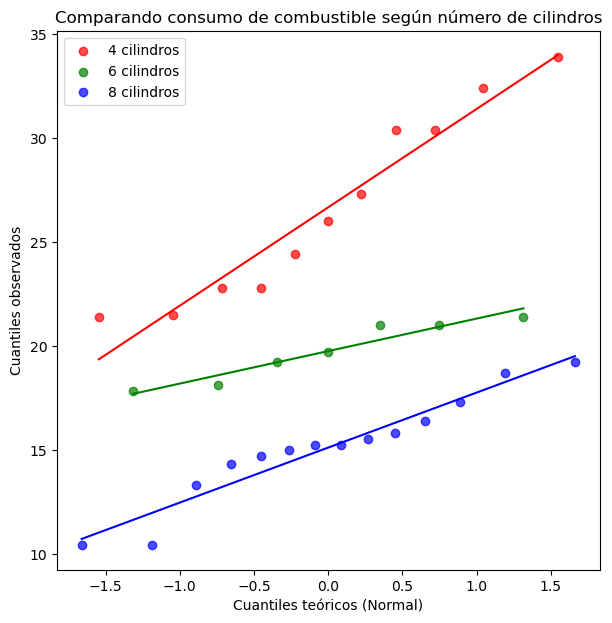

In [14]:
# Definir colores para cada grupo
colores = {4: 'red', 6: 'green', 8: 'blue'}

plt.figure(figsize=(7,7))

for c in [4, 6, 8]:
    datos = mtcars[mtcars['cyl'] == c]['mpg']

    # Obtener cuantiles teóricos y muestrales
    (osm, osr), (slope, intercept, r) = stats.probplot(datos, dist='norm')

    # Dibujar puntos
    plt.scatter(osm, osr, label=f"{c} cilindros", alpha=0.7, color=colores[c])

    # Dibujar recta de ajuste
    plt.plot(osm, slope*osm + intercept, color=colores[c])

plt.title('Comparando consumo de combustible según número de cilindros')
plt.xlabel('Cuantiles teóricos (Normal)')
plt.ylabel('Cuantiles observados')
plt.legend()
plt.show()

In [18]:
# Estadísticas por grupo
for cyl in [4, 6, 8]:
    datospre = mtcars[mtcars['cyl'] == cyl]
    datos = datospre['mpg']
    print()
    print(f'Cilindros: {cyl}')
    print(datos.describe())
    print(f'Desvío estándar: {np.std(datos, ddof=1)}')


Cilindros: 4
count    11.000000
mean     26.663636
std       4.509828
min      21.400000
25%      22.800000
50%      26.000000
75%      30.400000
max      33.900000
Name: mpg, dtype: float64
Desvío estándar: 4.509827652421481

Cilindros: 6
count     7.000000
mean     19.742857
std       1.453567
min      17.800000
25%      18.650000
50%      19.700000
75%      21.000000
max      21.400000
Name: mpg, dtype: float64
Desvío estándar: 1.453567041060419

Cilindros: 8
count    14.000000
mean     15.100000
std       2.560048
min      10.400000
25%      14.400000
50%      15.200000
75%      16.250000
max      19.200000
Name: mpg, dtype: float64
Desvío estándar: 2.5600480764716416


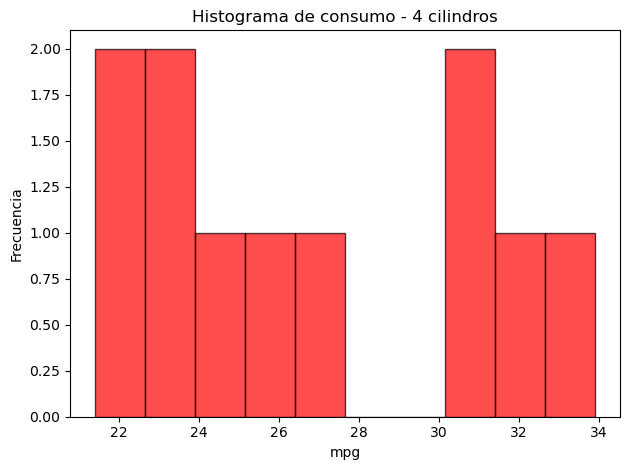

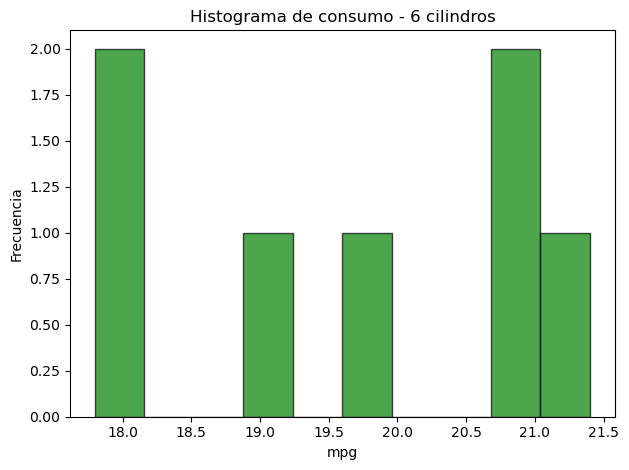

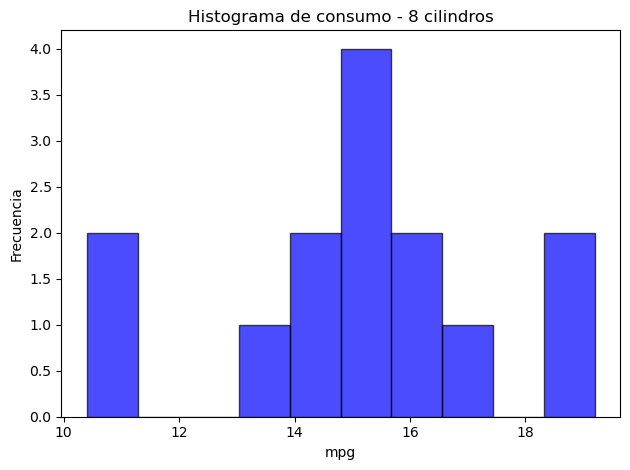

In [19]:
# Histogramas por grupo
colors = {4: 'red', 6: 'green', 8: 'blue'}
for cyl in [4, 6, 8]:
    datos = mtcars[mtcars['cyl'] == cyl]['mpg']
    plt.hist(datos, bins=10, color=colors[cyl], edgecolor='black', alpha=0.7)
    plt.title(f'Histograma de consumo - {cyl} cilindros')
    plt.xlabel('mpg')
    plt.ylabel('Frecuencia')
    plt.tight_layout()
    plt.show()